# Schwickert, Victora et al., JEM 2011 — data analysis

*A dynamic T cell–limited checkpoint regulates affinity-dependent B cell entry into the germinal center.*

Digitised data from the paper's figures, in `Research_files/immune_learning/schwieckert_victora_2011/data.csv`.
B1-8$^{\rm lo}$ and B1-8$^{\rm hi}$ B cells (low/high affinity for NP) are transferred alone or together with OT-II T cells and immunised with NP-OVA. The readouts are proliferation (CFSE dilution), GC entry (FAS/GL7, % of GC), antigen binding/presentation (MFI) and T–B conjugates.

Each row is one value read off a figure:

| column | meaning |
|---|---|
| `figure`, `panel` | figure and panel in the paper |
| `day`, `host` | days after immunisation; recipient (`MD4`, `WT`, `DEC205-/-`) |
| `lo_cells`, `hi_cells`, `ot2_cells` | cells transferred |
| `antigen`, `dose_ug_per_footpad` | immunisation |
| `readout`, `population` | what was measured, on which cells |
| `source` | `dot` (one mouse), `bar` (plotted mean), `text` (number quoted in the text), `flow_rep`/`hist_rep` (representative plot), `derived`, `pie` |
| `mouse`, `value`, `uncertainty`, `note` | mouse id (or `mean`/`rep`/`pooled`), value, digitisation uncertainty, comments |

The notebook goes figure by figure, checks the plotted means against the per-mouse dots, recomputes the derived quantities, and at the end collects the numbers that constrain the two-clone mode of `run_meanfield.py`.

In [1]:
import os, sys
sys.path.append('../../Codes/library/')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from paths import DRIVE
import mf_plotting as mfp          # palette only

plt.rcParams['text.usetex'] = False
plt.rcParams['font.size'] = 13

DATA_PATH = f'{DRIVE}/Research_files/immune_learning/schwieckert_victora_2011/data.csv'
OUTDIR = f'{DRIVE}/_Documents/Science/research_projects/Immune_System/figures/exponential_proofreading/schwickert_2011/'
SAVE = False                       # True -> write PDFs to OUTDIR
if SAVE:
    os.makedirs(OUTDIR, exist_ok=True)

def savefig(fig, name):
    if SAVE:
        fig.savefig(os.path.join(OUTDIR, name), bbox_inches='tight')

COLORS = {'B1-8lo': mfp.my_blue, 'B1-8hi': mfp.my_red, 'endogenous': mfp.my_grey,
          'B1-8hi_DEC+/+': mfp.my_purple2, 'B1-8hi_DEC-/-': mfp.my_green}

## Load and overview

In [2]:
df = pd.read_csv(DATA_PATH, dtype={'mouse': str, 'panel': str})
df['hi_lo'] = np.where(df.lo_cells > 0, df.hi_cells / df.lo_cells.replace(0, np.nan), np.nan)

COND = ['figure', 'panel', 'day', 'host', 'lo_cells', 'hi_cells', 'ot2_cells',
        'antigen', 'dose_ug_per_footpad']
KEYS = COND + ['readout', 'population']

print(f'{len(df)} rows')
df.groupby(['figure', 'panel', 'readout']).size().rename('rows').to_frame().T

436 rows


figure          1                          2                                \
panel           C                          B                                 
readout pct_of_GC cells_per_dividing_founder pct_CFSElow pct_FASint_GL7pos   
rows           28                          4           4                 4   

figure                                                               \
panel                                                                 
readout pct_cells_gen0 pct_cells_gen1 pct_cells_gen2 pct_cells_gen3   
rows                 4              4              4              4   

figure                                 ...                 5              \
panel                                  ...                 B           C   
readout pct_cells_gen4 pct_cells_gen5  ... pct_FASint_GL7pos pct_CFSElow   
rows                 4              4  ...                 6          36   

figure                            6                                \
panel                             B                   C             
readout pct_FASint_GL7pos pct_of_GC pct_of_PC pct_of_GC pct_of_PC   
rows                   38         6         6        30        24   

figure                   7                          
panel                    C                          
readout n_conjugates_total p_fisher pct_conjugates  
rows                     2        1              5  

[1 rows x 37 columns]

In [3]:
# digitisation notes left in the file
df[df.note.notna()].groupby('note').agg(rows=('value', 'size'),
                                        figures=('figure', lambda s: sorted(set(s))))

,rows,figures
note,,
Alexa647+ cells only,20,[3]
OVA vs CS comparison,1,[7]
authors' stated value,1,[7]
from text; similar across conditions,1,[3]
generation assignment uncertain (factor ~2),4,[2]
lower bound (pile-up),4,[2]
may include non-binding lo cells,1,[3]
per binding cell,1,[3]
pile-up bin,4,[2]


### Summary per condition

Per-mouse dots → `n`, `mean`, `sem`. Values from other sources (bar, text, representative plot, derived, pie) go in their own columns.

In [4]:
def summarize(d):
    dots = (d[d.source == 'dot'].groupby(KEYS, dropna=False)['value']
            .agg(n='size', mean='mean', sem='sem'))
    other = d[d.source != 'dot'].pivot_table(index=KEYS, columns='source',
                                              values='value', aggfunc='mean')
    return dots.join(other, how='outer').reset_index()

summary = summarize(df)
summary.head()

,figure,panel,day,host,lo_cells,hi_cells,ot2_cells,antigen,dose_ug_per_footpad,readout,population,n,mean,sem,bar,derived,flow_rep,hist_rep,pie,text
0,1,C,6.0,MD4,500000.0,0.0,200000.0,NP3-OVA,8,pct_of_GC,B1-8hi,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
1,1,C,6.0,MD4,500000.0,0.0,200000.0,NP3-OVA,8,pct_of_GC,B1-8lo,5.0,90.40,2.749545,90.0,NaN,88.0,NaN,NaN,89.0
2,1,C,6.0,MD4,500000.0,0.0,200000.0,NP3-OVA,8,pct_of_GC,endogenous,NaN,NaN,NaN,NaN,NaN,10.0,NaN,NaN,NaN
3,1,C,6.0,MD4,500000.0,500000.0,200000.0,NP3-OVA,8,pct_of_GC,B1-8hi,NaN,NaN,NaN,NaN,NaN,96.0,NaN,NaN,NaN
4,1,C,6.0,MD4,500000.0,500000.0,200000.0,NP3-OVA,8,pct_of_GC,B1-8lo,4.0,0.75,0.250000,1.0,NaN,1.0,NaN,NaN,1.0


### Consistency check: plotted bars vs per-mouse dots

If the digitisation is right, each bar should match the mean of its dots to within the stated `uncertainty`.

In [5]:
chk = summary.dropna(subset=['mean', 'bar']).copy()
unc = df[df.source == 'bar'].groupby(KEYS)['uncertainty'].max()
chk = chk.join(unc, on=KEYS)
chk['bar - mean'] = chk['bar'] - chk['mean']
chk['ok'] = chk['bar - mean'].abs() <= chk['uncertainty'] + chk['sem'].fillna(0)
print(f"{chk.ok.sum()}/{len(chk)} bars agree with their dots")
chk.loc[~chk.ok, KEYS + ['n', 'mean', 'sem', 'bar', 'uncertainty', 'bar - mean']]

55/55 bars agree with their dots


,figure,panel,day,host,lo_cells,hi_cells,ot2_cells,antigen,dose_ug_per_footpad,readout,population,n,mean,sem,bar,uncertainty,bar - mean


## Plotting helpers

In [6]:
def get(d=None, **kw):
    '''Rows of d (default df) matching column == value for every keyword.'''
    d = df if d is None else d
    m = np.ones(len(d), bool)
    for k, v in kw.items():
        m &= (d[k] == v).to_numpy()
    return d[m]

def dotbar(ax, groups, width=0.7, seed=0):
    '''groups: list of (label, rows, color). Bar = mean of dots +/- sem, plus jittered dots.
    With no dots, a hatched bar shows the bar/text/representative value.'''
    rng = np.random.default_rng(seed)
    for i, (lab, d, c) in enumerate(groups):
        dots = d[d.source == 'dot'].value.to_numpy()
        if len(dots):
            m, s = dots.mean(), (dots.std(ddof=1) / np.sqrt(len(dots)) if len(dots) > 1 else 0)
            ax.bar(i, m, width, color=c, alpha=0.35, edgecolor=c, lw=2)
            ax.errorbar(i, m, s, color='k', capsize=5, lw=1.5)
            ax.scatter(i + rng.uniform(-0.18, 0.18, len(dots)), dots, color=c,
                       edgecolor='k', zorder=3, s=40)
        else:
            alt = d[d.source.isin(['bar', 'text', 'flow_rep', 'hist_rep', 'derived', 'pie'])].value
            if len(alt):
                ax.bar(i, alt.iloc[0], width, color='none', edgecolor=c, lw=2, hatch='//')
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([g[0] for g in groups])
    ax.spines[['top', 'right']].set_visible(False)

def ratio_label(r):
    return 'lo alone' if r == 0 else f'hi:lo {r:g}:1'

## Figure 1C — high-affinity cells exclude B1-8$^{\rm lo}$ from the GC (day 6)

B1-8$^{\rm lo}$ share of the GC when transferred alone (MD4 or WT host) or 1:1 with B1-8$^{\rm hi}$ (MD4 host). MD4 hosts have no endogenous NP-specific B cells, so in WT hosts the lo cells also compete with endogenous cells.

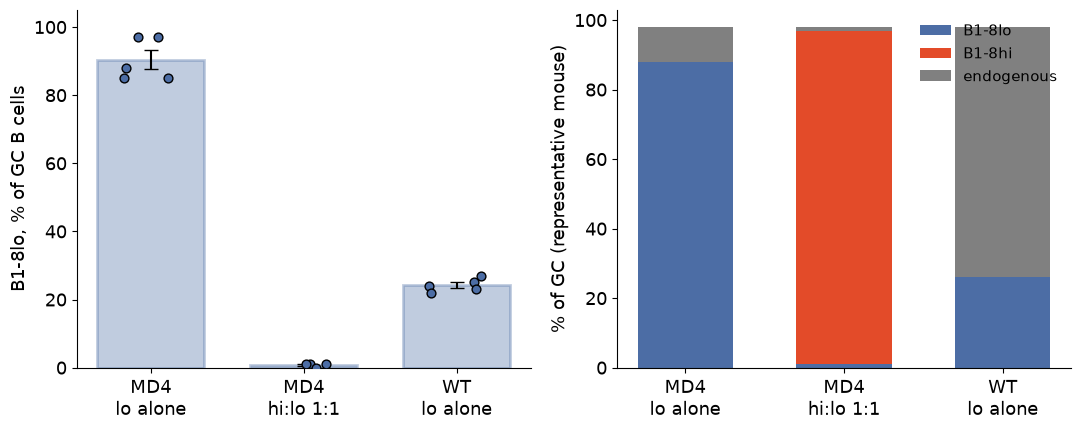

In [7]:
f1 = get(figure=1, readout='pct_of_GC')
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))

groups = [(f'{h}\n{ratio_label(r)}', get(f1, host=h, hi_lo=r, population='B1-8lo'), COLORS['B1-8lo'])
          for h, r in [('MD4', 0), ('MD4', 1), ('WT', 0)]]
dotbar(axs[0], groups)
axs[0].set_ylabel('B1-8lo, % of GC B cells')
axs[0].set_ylim(0, 105)

# GC composition from the representative flow plots
rep = f1[f1.source == 'flow_rep']
conds = [('MD4', 0), ('MD4', 1), ('WT', 0)]
bottom = np.zeros(len(conds))
for pop in ['B1-8lo', 'B1-8hi', 'endogenous']:
    vals = np.array([get(rep, host=h, hi_lo=r, population=pop).value.sum() for h, r in conds])
    axs[1].bar(range(len(conds)), vals, bottom=bottom, color=COLORS[pop], label=pop, width=0.6)
    bottom += vals
axs[1].set_xticks(range(len(conds)))
axs[1].set_xticklabels([f'{h}\n{ratio_label(r)}' for h, r in conds])
axs[1].set_ylabel('% of GC (representative mouse)')
axs[1].legend(frameon=False, fontsize=11)
axs[1].spines[['top', 'right']].set_visible(False)
fig.tight_layout(); savefig(fig, 'fig1C_GC_share.pdf')

## Figure 2 — B1-8$^{\rm hi}$ suppresses B1-8$^{\rm lo}$ proliferation and pre-GC entry (day 4)

2C: % of B1-8$^{\rm lo}$ cells that are CFSE$^{\rm lo}$ (divided) or FAS$^{\rm int}$GL7$^+$ (pre-GC), against the number of hi cells co-transferred.

size  mean  sem
readout           host hi_lo                 
pct_CFSElow       MD4  0.0       8  71.8  3.8
                       1.0       7  42.3  2.8
                       3.0       5  26.4  2.9
                  WT   0.0       8  52.8  3.1
pct_FASint_GL7pos MD4  0.0       9  49.4  4.4
                       1.0       7  12.4  1.1
                       3.0       5   4.6  0.4
                  WT   0.0       8  26.2  3.2

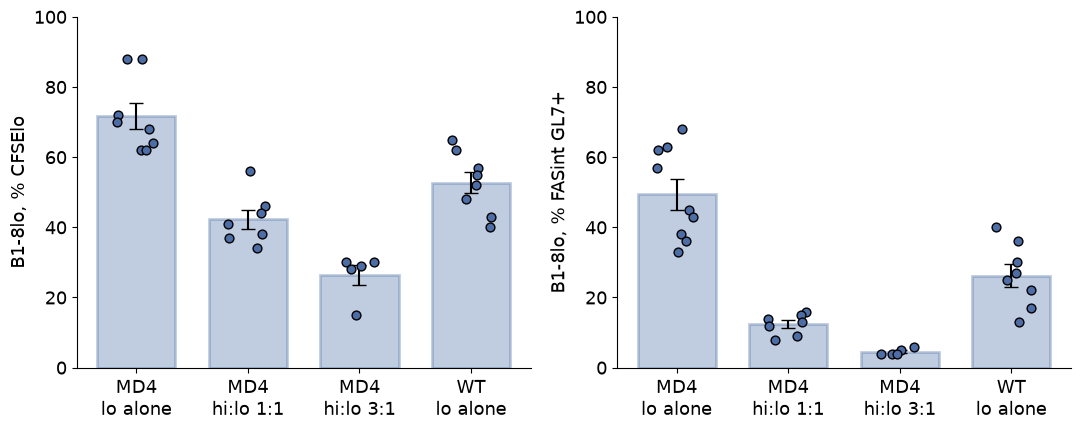

In [8]:
f2c = get(figure=2, panel='C')
conds = [('MD4', 0), ('MD4', 1), ('MD4', 3), ('WT', 0)]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (ro, ylab) in zip(axs, [('pct_CFSElow', '% CFSElo'),
                                ('pct_FASint_GL7pos', '% FASint GL7+')]):
    groups = [(f'{h}\n{ratio_label(r)}', get(f2c, host=h, hi_lo=r, readout=ro), COLORS['B1-8lo'])
              for h, r in conds]
    dotbar(ax, groups)
    ax.set_ylabel(f'B1-8lo, {ylab}')
    ax.set_ylim(0, 100)
fig.tight_layout(); savefig(fig, 'fig2C_proliferation.pdf')

f2c[f2c.source == 'dot'].groupby(['readout', 'host', 'hi_lo']).value.agg(['size', 'mean', 'sem']).round(1)

### 2B — division profiles and precursor-cohort analysis

A founder that has divided $k$ times has $2^k$ descendants. So the number of founders behind generation $k$ is $f_k = c_k/2^k$, where $c_k$ is the % of cells in generation $k$. From this:

* fraction of founders that divided: $\sum_{k\ge1} f_k / \sum_{k\ge0} f_k$,
* cells per dividing founder (burst size): $\sum_{k\ge1} c_k / \sum_{k\ge1} f_k$,
* mean number of divisions of dividing founders: $\sum_{k\ge1} k f_k / \sum_{k\ge1} f_k$.

The last bin is 9+ divisions and is counted as 9, so it overestimates founders there and underestimates burst size; the generation assignment is uncertain by about a factor of 2 (see notes).

In [9]:
f2b = get(figure=2, panel='B')
gens = f2b[f2b.readout.str.startswith('pct_cells_gen')].copy()
gens['k'] = gens.readout.str.extract(r'gen(\d+)').astype(int)

def cohort(g):
    g = g.sort_values('k')
    c, k = g.value.to_numpy(), g.k.to_numpy()
    f = c / 2.0 ** k
    div = k >= 1
    return pd.Series({'pct_founders_divided': 100 * f[div].sum() / f.sum(),
                      'cells_per_dividing_founder': c[div].sum() / f[div].sum(),
                      'mean_divisions_of_dividers': (k[div] * f[div]).sum() / f[div].sum()})

conds = [('MD4', 0), ('MD4', 1), ('MD4', 3), ('WT', 0)]
rows = []
for h, r in conds:
    g = get(gens, host=h, hi_lo=r)
    out = cohort(g)
    for ro in ['pct_founders_divided', 'cells_per_dividing_founder']:
        d = get(f2b, host=h, hi_lo=r, readout=ro)
        out[ro + ' (file)'] = d.value.iloc[0] if len(d) else np.nan
    rows.append(pd.Series({'host': h, 'hi:lo': r, **out}))
coh = pd.DataFrame(rows)
coh.round(2)

,host,hi:lo,pct_founders_divided,cells_per_dividing_founder,mean_divisions_of_dividers,pct_founders_divided (file),cells_per_dividing_founder (file)
0,MD4,0,16.85,36.18,3.62,17.0,36.0
1,MD4,1,3.53,16.75,2.62,3.5,17.0
2,MD4,3,4.34,9.00,2.23,4.4,9.0
3,WT,0,8.43,11.80,2.32,8.0,12.0


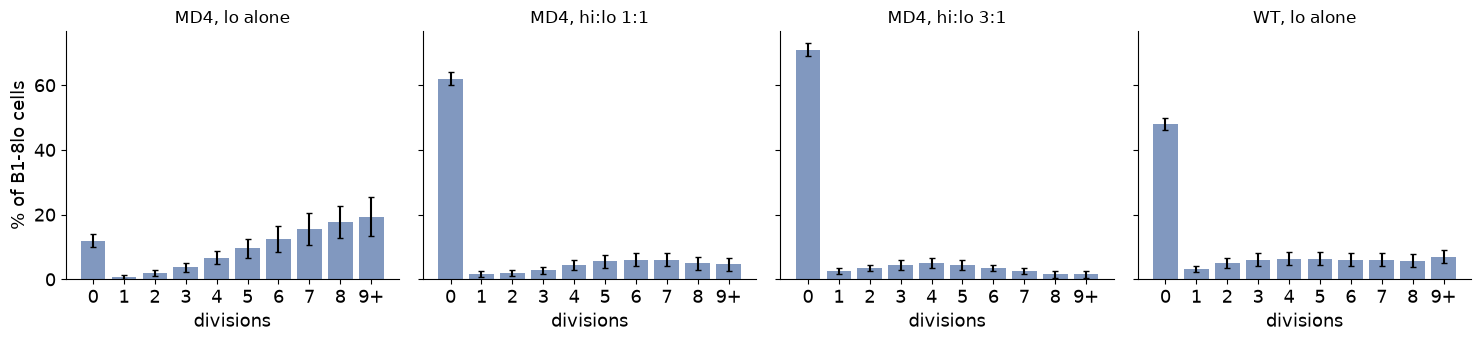

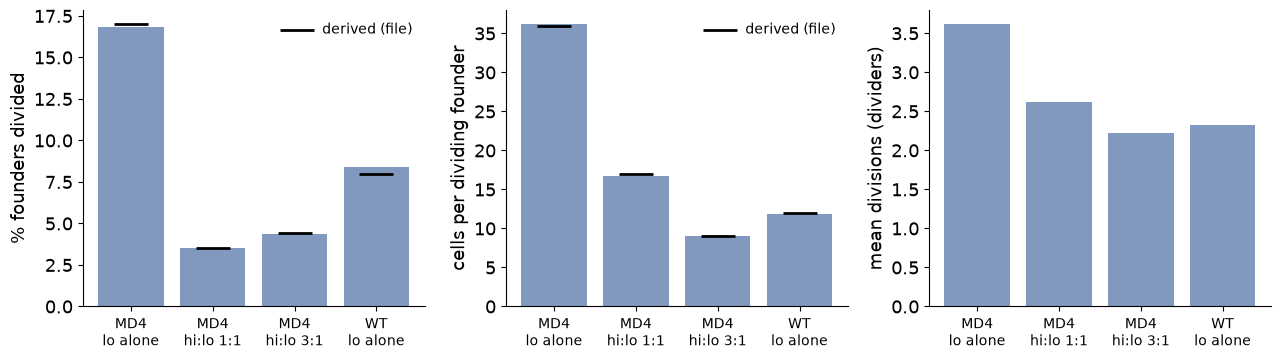

In [10]:
fig, axs = plt.subplots(1, len(conds), figsize=(15, 3.6), sharey=True)
for ax, (h, r) in zip(axs, conds):
    g = get(gens, host=h, hi_lo=r).sort_values('k')
    ax.bar(g.k, g.value, yerr=g.uncertainty, color=COLORS['B1-8lo'], alpha=0.7, capsize=2)
    ax.set_title(f'{h}, {ratio_label(r)}', fontsize=12)
    ax.set_xticks(range(10)); ax.set_xticklabels([*map(str, range(9)), '9+'])
    ax.set_xlabel('divisions')
    ax.spines[['top', 'right']].set_visible(False)
axs[0].set_ylabel('% of B1-8lo cells')
fig.tight_layout(); savefig(fig, 'fig2B_generations.pdf')

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
x = np.arange(len(coh)); labels = [f'{h}\n{ratio_label(r)}' for h, r in conds]
for ax, col, ylab in zip(axs, ['pct_founders_divided', 'cells_per_dividing_founder', 'mean_divisions_of_dividers'],
                         ['% founders divided', 'cells per dividing founder', 'mean divisions (dividers)']):
    ax.bar(x, coh[col], color=COLORS['B1-8lo'], alpha=0.7)
    if col + ' (file)' in coh:
        ax.scatter(x, coh[col + ' (file)'], marker='_', s=600, color='k', lw=2, label='derived (file)', zorder=3)
        ax.legend(frameon=False, fontsize=10)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=10); ax.set_ylabel(ylab)
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); savefig(fig, 'fig2B_cohort.pdf')

## Figure 3 — antigen binding and presentation (day 0.67, NP-E$\alpha$)

* 3B: NP-antigen capture (Alexa647 MFI).
* 3C: presented peptide–MHC (YAe MFI).

Hi and lo cells are measured in the same co-transferred mouse, so the hi/lo ratio can be taken mouse by mouse (assuming the `mouse` ids are paired across populations).

,n,per_mouse_mean,sem,ratio_of_means,file
readout,,,,,
MFI_Alexa647,4,2.78,0.22,2.82,2.8
MFI_YAe,4,3.61,0.11,3.60,3.6


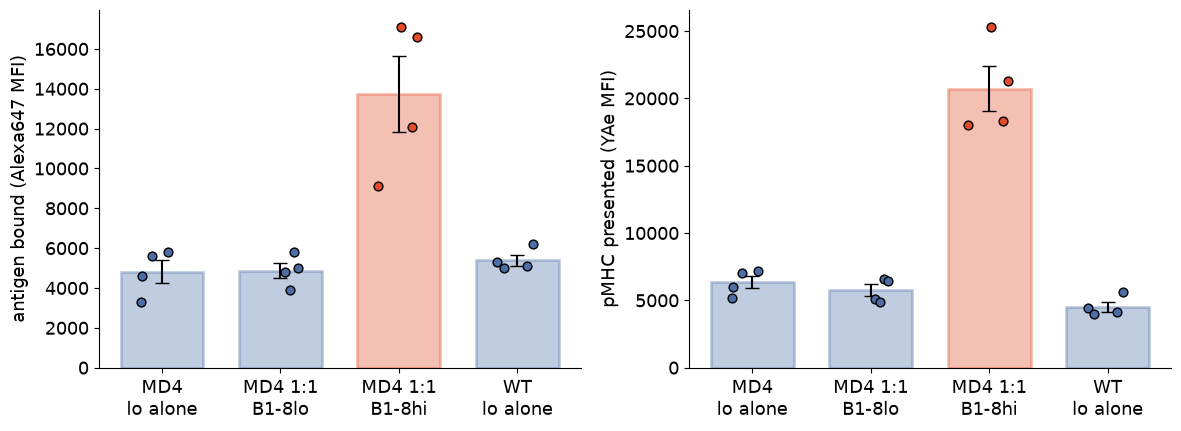

In [11]:
f3 = get(figure=3)
groups_def = [('MD4\nlo alone', dict(host='MD4', hi_lo=0, population='B1-8lo'), 'B1-8lo'),
              ('MD4 1:1\nB1-8lo', dict(host='MD4', hi_lo=1, population='B1-8lo'), 'B1-8lo'),
              ('MD4 1:1\nB1-8hi', dict(host='MD4', hi_lo=1, population='B1-8hi'), 'B1-8hi'),
              ('WT\nlo alone', dict(host='WT', hi_lo=0, population='B1-8lo'), 'B1-8lo')]
fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (ro, ylab) in zip(axs, [('MFI_Alexa647', 'antigen bound (Alexa647 MFI)'),
                                ('MFI_YAe', 'pMHC presented (YAe MFI)')]):
    dotbar(ax, [(lab, get(f3, readout=ro, **kw), COLORS[c]) for lab, kw, c in groups_def])
    ax.set_ylabel(ylab)
fig.tight_layout(); savefig(fig, 'fig3_binding_presentation.pdf')

ratios = []
for ro in ['MFI_Alexa647', 'MFI_YAe']:
    hi = get(f3, readout=ro, host='MD4', hi_lo=1, population='B1-8hi', source='dot').set_index('mouse').value
    lo = get(f3, readout=ro, host='MD4', hi_lo=1, population='B1-8lo', source='dot').set_index('mouse').value
    r = (hi / lo).dropna()
    file_r = get(f3, readout='ratio_hi_lo_' + ro.split('_')[1]).value
    ratios.append(dict(readout=ro, n=len(r), per_mouse_mean=r.mean(), sem=r.sem(),
                       ratio_of_means=hi.mean() / lo.mean(),
                       file=file_r.iloc[0] if len(file_r) else np.nan))
ratios = pd.DataFrame(ratios).set_index('readout')
ratios.round(2)

**Link to the model.** In `mf_lib`, $\pi \propto \psi(\Delta G) = (1+e^{\Delta G+1/2})^{-\eta}$, which is $\approx e^{-\eta(\Delta G + 1/2)}$ when $\Delta G \gtrsim 1$. A presentation ratio $r = \pi_{\rm hi}/\pi_{\rm lo}$ then corresponds to an affinity gap $\Delta\Delta G \approx \ln r / \eta$ in `two_clone`. This is only an estimate: it assumes the same antigen access and that YAe is linear in $\pi$. The activation rate scales as $\pi^{n}$, so its ratio is $r^{n}$.

In [12]:
ETA, HILL = 1.0, 2.0                       # BASE in run_meanfield.py
r_pres = ratios.loc['MFI_YAe', 'per_mouse_mean']
r_bind = ratios.loc['MFI_Alexa647', 'per_mouse_mean']
print(f'presentation ratio hi/lo = {r_pres:.2f}  ->  gap ~ ln(r)/eta = {np.log(r_pres)/ETA:.2f}')
print(f'binding ratio hi/lo      = {r_bind:.2f}  ->  gap ~ {np.log(r_bind)/ETA:.2f}')
print(f'activation-rate ratio (pi^n, n={HILL:g}) ~ {r_pres**HILL:.1f}')

presentation ratio hi/lo = 3.61  ->  gap ~ ln(r)/eta = 1.28
binding ratio hi/lo      = 2.78  ->  gap ~ 1.02
activation-rate ratio (pi^n, n=2) ~ 13.0


## Figure 4 — more antigen partly relieves the suppression (day 4)

% CFSE$^{\rm lo}$ and % FAS$^+$GL7$^+$ of B1-8$^{\rm lo}$, alone or 1:1 with B1-8$^{\rm hi}$, against the NP-OVA dose. Suppression ratio = (with hi) / (lo alone). It is recomputed from the dots and compared with the `derived` rows.

,readout,dose,ratio,err,file
0,pct_CFSElow,5,0.391,0.068,0.43
1,pct_CFSElow,50,0.438,0.043,0.43
2,pct_CFSElow,200,0.652,0.044,0.65
3,pct_FASpos_GL7pos,5,0.312,0.087,0.32
4,pct_FASpos_GL7pos,50,0.344,0.038,0.34
5,pct_FASpos_GL7pos,200,0.519,0.067,0.51


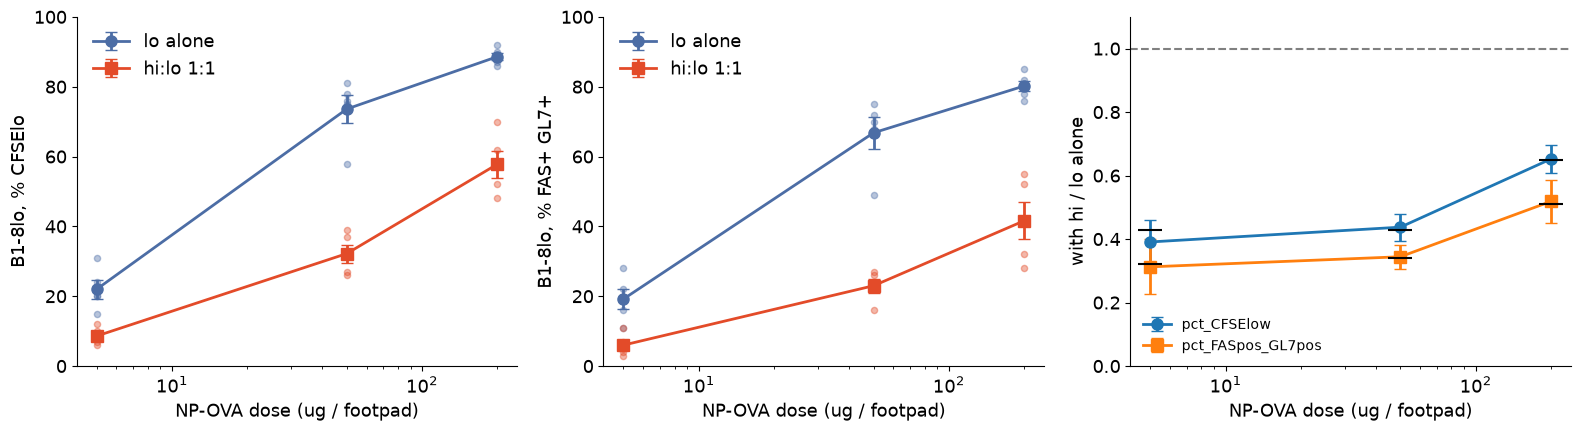

In [13]:
f4 = get(figure=4, panel='C')
doses = sorted(f4.dose_ug_per_footpad.unique())
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5))
supp = []
for ax, (ro, ylab) in zip(axs[:2], [('pct_CFSElow', '% CFSElo'), ('pct_FASpos_GL7pos', '% FAS+ GL7+')]):
    for r, c, mk in [(0, COLORS['B1-8lo'], 'o'), (1, COLORS['B1-8hi'], 's')]:
        s = (get(f4, readout=ro, hi_lo=r, source='dot').groupby('dose_ug_per_footpad').value
             .agg(['mean', 'sem']).reindex(doses))
        ax.errorbar(doses, s['mean'], s['sem'], color=c, marker=mk, ms=8, capsize=4, lw=2,
                    label=ratio_label(r))
        d = get(f4, readout=ro, hi_lo=r, source='dot')
        ax.scatter(d.dose_ug_per_footpad, d.value, color=c, alpha=0.4, s=20)
    ax.set_xscale('log'); ax.set_xlabel('NP-OVA dose (ug / footpad)'); ax.set_ylabel(f'B1-8lo, {ylab}')
    ax.set_ylim(0, 100); ax.legend(frameon=False)
    ax.spines[['top', 'right']].set_visible(False)

    alone = get(f4, readout=ro, hi_lo=0, source='dot').groupby('dose_ug_per_footpad').value
    with_hi = get(f4, readout=ro, hi_lo=1, source='dot').groupby('dose_ug_per_footpad').value
    m0, m1 = alone.mean(), with_hi.mean()
    rel = np.sqrt((alone.sem() / m0) ** 2 + (with_hi.sem() / m1) ** 2)
    key = 'suppression_ratio_' + ('CFSElow' if ro == 'pct_CFSElow' else 'FASGL7')
    file_v = get(f4, readout=key).set_index('dose_ug_per_footpad').value
    for dose in doses:
        supp.append(dict(readout=ro, dose=dose, ratio=m1[dose] / m0[dose],
                         err=m1[dose] / m0[dose] * rel[dose], file=file_v.get(dose, np.nan)))
supp = pd.DataFrame(supp)

ax = axs[2]
for (ro, g), mk in zip(supp.groupby('readout', sort=False), ['o', 's']):
    ax.errorbar(g.dose, g.ratio, g.err, marker=mk, ms=8, capsize=4, lw=2, label=ro)
    ax.scatter(g.dose, g.file, marker='_', s=300, color='k', zorder=3)
ax.axhline(1, color='grey', ls='--')
ax.set_xscale('log'); ax.set_ylim(0, 1.1)
ax.set_xlabel('NP-OVA dose (ug / footpad)'); ax.set_ylabel('with hi / lo alone')
ax.legend(frameon=False, fontsize=10); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); savefig(fig, 'fig4_dose.pdf')
supp.round(3)

## Figures 5–6 — extra T-cell help via DEC-205 rescues/promotes entry

DEC205$^{+/+}$ and DEC205$^{-/-}$ B1-8$^{\rm hi}$ cells are co-transferred into DEC205$^{-/-}$ hosts. $\alpha$DEC-OVA delivers OVA (the T-cell epitope) only to DEC205$^{+/+}$ B cells, so it raises their pMHC and T-cell help without changing BCR affinity. $\alpha$DEC-CS (control antigen) and PBS are the controls.

,readout,treatment,DEC_pos,DEC_neg,share_DEC_pos
0,pct_of_GC,PBS,49.75,39.50,0.56
1,pct_of_GC,aDEC-CS,44.50,40.25,0.53
2,pct_of_GC,aDEC-OVA,91.00,1.25,0.99
3,pct_of_PC,PBS,34.33,31.67,0.52
4,pct_of_PC,aDEC-CS,42.50,37.50,0.53
5,pct_of_PC,aDEC-OVA,94.75,0.00,1.00


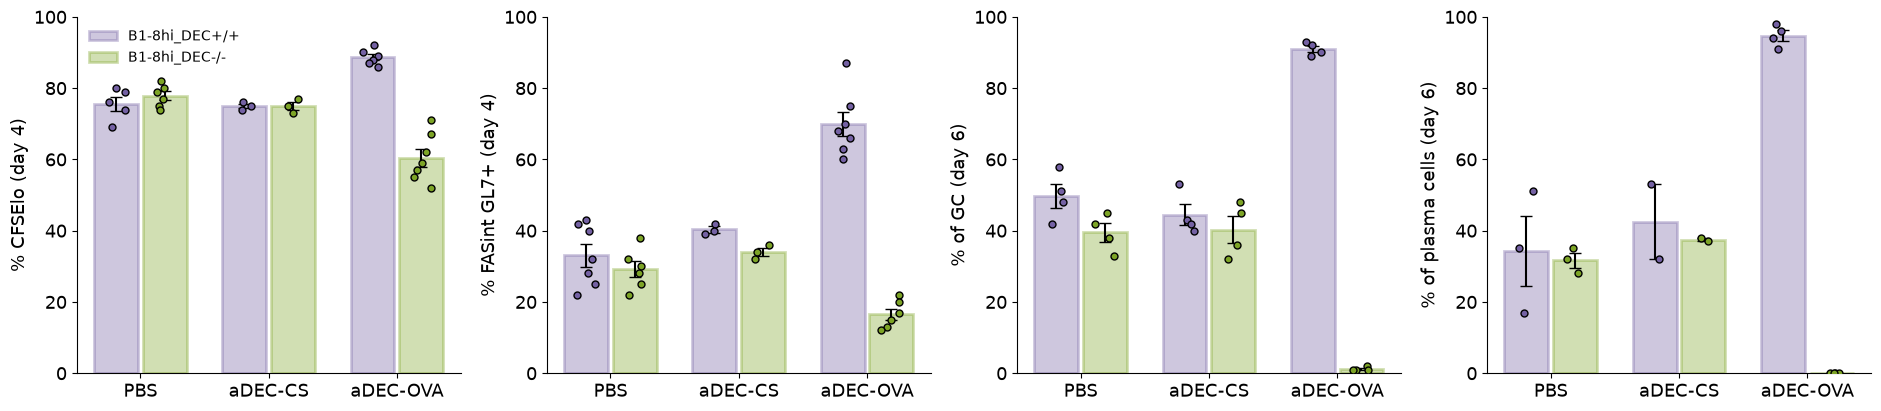

In [14]:
treat = ['NP3-OVA+PBS', 'NP3-OVA+aDEC-CS', 'NP3-OVA+aDEC-OVA']
tlab = ['PBS', 'aDEC-CS', 'aDEC-OVA']
pops = ['B1-8hi_DEC+/+', 'B1-8hi_DEC-/-']
panels = [(5, 4.0, 'pct_CFSElow', '% CFSElo (day 4)'),
          (5, 4.0, 'pct_FASint_GL7pos', '% FASint GL7+ (day 4)'),
          (6, 6.0, 'pct_of_GC', '% of GC (day 6)'),
          (6, 6.0, 'pct_of_PC', '% of plasma cells (day 6)')]
fig, axs = plt.subplots(1, 4, figsize=(19, 4.3))
w = 0.38
rng = np.random.default_rng(1)
for ax, (fg, day, ro, ylab) in zip(axs, panels):
    for j, pop in enumerate(pops):
        for i, t in enumerate(treat):
            d = get(figure=fg, panel='C', readout=ro, population=pop, antigen=t, source='dot')
            x = i + (j - 0.5) * w
            if len(d):
                ax.bar(x, d.value.mean(), w * 0.9, color=COLORS[pop], alpha=0.35, edgecolor=COLORS[pop], lw=2,
                       label=pop if i == 0 else None)
                ax.errorbar(x, d.value.mean(), d.value.sem() if len(d) > 1 else 0, color='k', capsize=4)
                ax.scatter(x + rng.uniform(-0.08, 0.08, len(d)), d.value, color=COLORS[pop], edgecolor='k', s=25, zorder=3)
    ax.set_xticks(range(3)); ax.set_xticklabels(tlab); ax.set_ylabel(ylab); ax.set_ylim(0, 100)
    ax.spines[['top', 'right']].set_visible(False)
axs[0].legend(frameon=False, fontsize=10)
fig.tight_layout(); savefig(fig, 'fig5_6_DEC205.pdf')

# share of the transferred GC / PC compartment taken by DEC+/+ cells
share = []
for ro in ['pct_of_GC', 'pct_of_PC']:
    for t, tl in zip(treat, tlab):
        a = get(figure=6, panel='C', readout=ro, population=pops[0], antigen=t, source='dot').value.mean()
        b = get(figure=6, panel='C', readout=ro, population=pops[1], antigen=t, source='dot').value.mean()
        share.append(dict(readout=ro, treatment=tl, DEC_pos=a, DEC_neg=b, share_DEC_pos=a / (a + b)))
pd.DataFrame(share).round(2)

## Figure 7 — T–B conjugates (day 1.67)

The file gives the total number of conjugates and the % involving DEC205$^{+/+}$ cells. For $\alpha$DEC-OVA the pie (70%) and the text (90%) disagree. Below, Fisher's exact test is recomputed for both readings and compared with the reported $p = 4\times10^{-4}$.

In [15]:
f7 = get(figure=7)
n_cs = get(f7, antigen='NP3-OVA+aDEC-CS', readout='n_conjugates_total').value.iloc[0]
n_ova = get(f7, antigen='NP3-OVA+aDEC-OVA', readout='n_conjugates_total').value.iloc[0]
pos_cs = get(f7, antigen='NP3-OVA+aDEC-CS', readout='pct_conjugates', population='B1-8hi_DEC+/+').value.iloc[0]
p_rep = get(f7, readout='p_fisher').value.iloc[0]

rows = []
for src in ['pie', 'text']:
    pos_ova = get(f7, antigen='NP3-OVA+aDEC-OVA', readout='pct_conjugates',
                  population='B1-8hi_DEC+/+', source=src).value.iloc[0]
    table = np.round([[n_cs * pos_cs / 100, n_cs * (1 - pos_cs / 100)],
                      [n_ova * pos_ova / 100, n_ova * (1 - pos_ova / 100)]]).astype(int)
    rows.append(dict(aDEC_OVA_source=src, pct_DEC_pos_OVA=pos_ova,
                     table=table.tolist(), p_fisher=stats.fisher_exact(table)[1], p_reported=p_rep))
pd.DataFrame(rows)

,aDEC_OVA_source,pct_DEC_pos_OVA,table,p_fisher,p_reported
0,pie,70.0,"[[42, 28], [28, 12]]",0.312276,0.0004
1,text,90.0,"[[42, 28], [36, 4]]",0.000901,0.0004


## Targets for the two-clone model

The numbers from above that a two-clone run (`python run_meanfield.py two_clone`, with explicit T-help limitation) should reproduce. Clone 1 = B1-8$^{\rm hi}$, clone 2 = B1-8$^{\rm lo}$; `ratio` = lo/hi = 1/(hi:lo).

In [16]:
def dots_mean(**kw):
    d = get(source='dot', **kw).value
    return d.mean(), d.sem(), len(d)

T = []
def add(quantity, condition, mean, sem=np.nan, n=np.nan, fig=''):
    T.append(dict(quantity=quantity, condition=condition, mean=mean, sem=sem, n=n, figure=fig))

for h, r in [('MD4', 0), ('MD4', 1), ('WT', 0)]:
    add('B1-8lo % of GC, day 6', f'{h}, {ratio_label(r)}',
        *dots_mean(figure=1, readout='pct_of_GC', population='B1-8lo', host=h, hi_lo=r), fig='1C')
for h, r in [('MD4', 0), ('MD4', 1), ('MD4', 3), ('WT', 0)]:
    for ro in ['pct_CFSElow', 'pct_FASint_GL7pos']:
        add(f'B1-8lo {ro}, day 4', f'{h}, {ratio_label(r)}',
            *dots_mean(figure=2, panel='C', readout=ro, host=h, hi_lo=r), fig='2C')
for _, row in coh.iterrows():
    for col in ['pct_founders_divided', 'cells_per_dividing_founder']:
        add(f'B1-8lo {col}, day 4', f"{row.host}, {ratio_label(row['hi:lo'])}", row[col], fig='2B')
for ro, row in ratios.iterrows():
    add(f'hi/lo {ro}', 'MD4 1:1, day 0.67', row['per_mouse_mean'], row['sem'], row['n'], fig='3')
for _, row in supp.iterrows():
    add(f'suppression {row.readout}', f'dose {row.dose:g} ug', row.ratio, row.err, fig='4C')
for row in share:
    add(f'DEC+/+ share of {row["readout"]}', row['treatment'], row['share_DEC_pos'], fig='6C')

targets = pd.DataFrame(T)
targets.round(3)

,quantity,condition,mean,sem,n,figure
0,"B1-8lo % of GC, day 6","MD4, lo alone",90.400,2.750,5.0,1C
1,"B1-8lo % of GC, day 6","MD4, hi:lo 1:1",0.750,0.250,4.0,1C
2,"B1-8lo % of GC, day 6","WT, lo alone",24.200,0.860,5.0,1C
3,"B1-8lo pct_CFSElow, day 4","MD4, lo alone",71.750,3.769,8.0,2C
4,"B1-8lo pct_FASint_GL7pos, day 4","MD4, lo alone",49.444,4.388,9.0,2C
5,"B1-8lo pct_CFSElow, day 4","MD4, hi:lo 1:1",42.286,2.766,7.0,2C
6,"B1-8lo pct_FASint_GL7pos, day 4","MD4, hi:lo 1:1",12.429,1.131,7.0,2C
7,"B1-8lo pct_CFSElow, day 4","MD4, hi:lo 3:1",26.400,2.874,5.0,2C
8,"B1-8lo pct_FASint_GL7pos, day 4","MD4, hi:lo 3:1",4.600,0.400,5.0,2C
9,"B1-8lo pct_CFSElow, day 4","WT, lo alone",52.750,3.104,8.0,2C
